# Dubai Property Market 2026 — What the Land Department data says

**Author:** Nitheesha M V · **Data:** Dubai Land Department (DLD) Open Data, every registered sale in 2026 to date

**Business questions**
1. How busy is the market and is it still growing month to month?
2. How much of it is off-plan (bought before completion) and is that changing?
3. Which areas get the most demand, and which are cheap or expensive per sq ft?
4. What do buyers actually buy (apartments vs villas, bedrooms, budget)?
5. Where does an investor earn the best rental yield?

**Pipeline:** DLD CSV export → Python cleaning (`src/01_clean.py`) → DuckDB SQL marts (`sql/*.sql`) → this notebook → dashboard + Power BI.

In [1]:
import duckdb, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mt
from pathlib import Path

con = duckdb.connect('../data/dubai_real_estate.duckdb', read_only=True)
q = lambda sql: con.execute(sql).df()
sql_file = lambda name: q(Path(f'../sql/{name}.sql').read_text())

BLUE, ORANGE, INK, MUTED, GRID = '#2a78d6', '#eb6834', '#0b0b0b', '#898781', '#e1e0d9'
plt.rcParams.update({
    'figure.figsize': (10, 4.2), 'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.spines.left': False, 'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'axes.grid.axis': 'y',
    'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True, 'xtick.color': MUTED,
    'ytick.color': MUTED, 'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'font.family': 'Segoe UI', 'axes.labelcolor': MUTED,
})
aed = mt.FuncFormatter(lambda x, _: f'{x/1e9:.0f} bn' if x >= 1e9 else f'{x/1e6:.1f} M' if x >= 1e6 else f'{x:,.0f}')
pd.options.display.float_format = '{:,.1f}'.format

## 1. The data and how it was cleaned

In [2]:
log = pd.read_csv('../data/clean/cleaning_log.csv', index_col=0)
display(log)
overview = q('''SELECT COUNT(*) AS sales, MIN(transaction_date)::DATE AS first_day, MAX(transaction_date)::DATE AS last_day,
                       COUNT(DISTINCT area) AS areas, COUNT(DISTINCT project) AS projects,
                       SUM(price_aed) AS total_value_aed FROM sales''')
overview

,rows
raw_rows,122551
after_dedupe,122491
valid_price_and_size,122197
dropped_price_outliers,456
clean_rows,121741
rent_rows,25988


,sales,first_day,last_day,areas,projects,total_value_aed
0,121741,2026-01-01,2026-09-30,246,2944,"376,444,647,785.8"


**Cleaning decisions (and why):**
- The export repeats a sale once per nearby metro station → kept **one row per DLD transaction number**.
- Buyer/seller counts are always 0 and the master-project field is >99% empty in the open export → dropped.
- DLD's "Unit" type mixes flats, offices, shops and hotel rooms → mapped to **Apartment, Villa, Commercial, Hotel, Land** segments.
- Homes priced below 100 or above 20,000 AED per sq ft are data-entry errors → dropped. Land is kept as is (plots on the city edge legitimately sell for <100 AED/sq ft).
- Area names arrive in mixed casing ("BUSINESS BAY" vs "Al Yelayiss 1") → normalised.

In [3]:
q('''SELECT segment, COUNT(*) AS sales, ROUND(100.0*COUNT(*)/SUM(COUNT(*)) OVER (),1) AS share_pct,
            SUM(price_aed) AS value_aed, MEDIAN(price_aed) AS median_price_aed
     FROM sales GROUP BY segment ORDER BY sales DESC''')

,segment,sales,share_pct,value_aed,median_price_aed
0,Apartment,95510,78.5,"174,686,447,539.7","1,225,636.0"
1,Villa,9481,7.8,"37,419,651,618.3","3,250,000.0"
2,Land,9409,7.7,"134,131,465,644.3","6,962,777.0"
3,Commercial,4861,4.0,"24,956,070,700.6","2,540,300.0"
4,Hotel,2455,2.0,"4,343,549,527.3","929,200.0"
5,Other,25,0.0,"907,462,755.5","3,850,000.0"


## 2. Market pulse: volume and price by month

,month,transactions,total_value_aed,median_price_aed,median_price_sqft,offplan_share_pct,volume_mom_pct,price_sqft_mom_pct
0,2026-01-01,17192,"71,994,279,398.8","1,615,334.9","1,791.0",64.8,NaN,NaN
1,2026-02-01,16966,"60,655,747,994.1","1,500,000.0","1,760.0",62.1,-1.3,-1.7
2,2026-03-01,13457,"43,550,275,140.1","1,527,865.0","1,749.0",70.1,-20.7,-0.6
3,2026-04-01,13951,"47,943,306,877.1","1,590,000.0","1,823.0",73.1,3.7,4.3
4,2026-05-01,10232,"28,856,621,692.3","1,136,926.5","1,636.0",72.4,-26.7,-10.3
5,2026-06-01,13882,"33,179,804,383.9","1,121,714.0","1,698.0",72.6,35.7,3.8
6,2026-07-01,13480,"34,237,423,417.0","1,079,000.0","1,690.0",69.9,-2.9,-0.5
7,2026-08-01,11543,"27,566,569,103.8","1,151,000.0","1,696.0",68.9,-14.4,0.4
8,2026-09-01,11038,"28,460,619,778.6","1,240,564.0","1,652.0",65.8,-4.4,-2.6


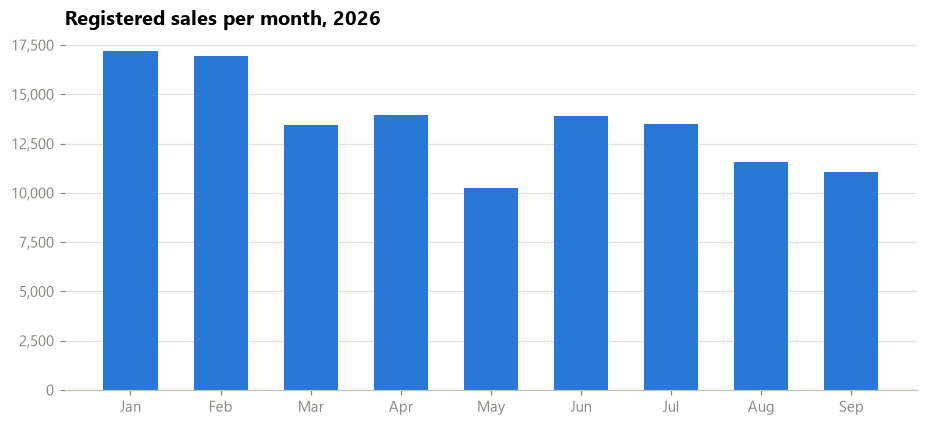

In [4]:
monthly = sql_file('01_monthly_market')
display(monthly)
fig, ax = plt.subplots()
ax.bar(monthly['month'].dt.strftime('%b'), monthly['transactions'], color=BLUE, width=0.6)
ax.set_title('Registered sales per month, 2026')
ax.yaxis.set_major_formatter(mt.StrMethodFormatter('{x:,.0f}'))
plt.show()

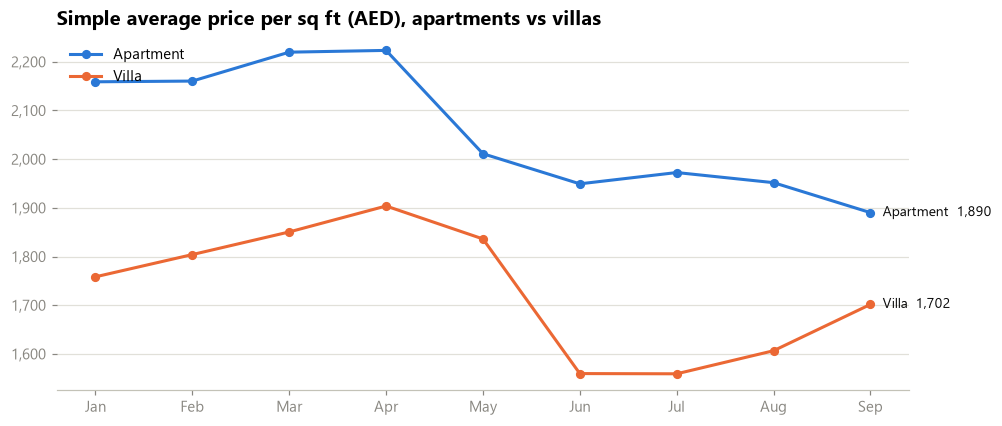

In [5]:
price = q('''SELECT month, segment, SUM(price_aed)/SUM(size_sqft) AS avg_price_sqft, COUNT(*) AS n
              FROM sales WHERE segment IN ('Apartment','Villa') GROUP BY ALL ORDER BY month''')
fig, ax = plt.subplots()
for seg, color in [('Apartment', BLUE), ('Villa', ORANGE)]:
    d = price[price.segment == seg]
    ax.plot(d['month'].dt.strftime('%b'), d['avg_price_sqft'], color=color, lw=2, marker='o', ms=5, label=seg)
    ax.annotate(f"{seg}  {d['avg_price_sqft'].iloc[-1]:,.0f}", (len(d) - 1, d['avg_price_sqft'].iloc[-1]),
                xytext=(8, 0), textcoords='offset points', va='center', color=INK, fontsize=9)
ax.set_title('Simple average price per sq ft (AED), apartments vs villas')
ax.legend(frameon=False, loc='upper left'); ax.yaxis.set_major_formatter(mt.StrMethodFormatter('{x:,.0f}'))
plt.show()

### Is the price change real? A like-for-like index

The simple city-wide average moves whenever the **mix** changes: a month with more sales in cheap areas
pulls it down even if no home got cheaper. To separate the two effects I built a fixed-basket index
(`sql/07_price_index.sql`): the same areas every month, each weighted by its share of sales over the period.

,month,basket_areas,like_for_like_price_sqft,price_index,raw_avg_price_sqft,raw_index
0,2026-01-01,47,"1,773.0",100.0,"2,159.0",100.0
1,2026-02-01,47,"1,748.0",98.6,"2,160.0",100.1
2,2026-03-01,47,"1,816.0",102.4,"2,220.0",102.8
3,2026-04-01,47,"1,846.0",104.1,"2,223.0",103.0
4,2026-05-01,47,"1,780.0",100.4,"2,011.0",93.2
5,2026-06-01,47,"1,790.0",101.0,"1,949.0",90.3
6,2026-07-01,47,"1,755.0",99.0,"1,972.0",91.4
7,2026-08-01,47,"1,766.0",99.6,"1,952.0",90.4
8,2026-09-01,47,"1,732.0",97.7,"1,890.0",87.6


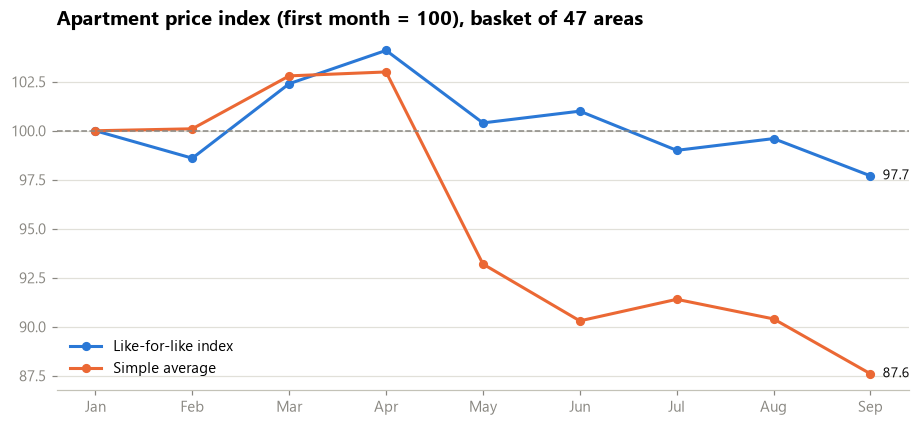

Latest month: like-for-like -2.3%, simple average -12.4% -> 10.1 points of the simple average's move come from the mix of areas, not from prices.


In [6]:
idx = sql_file('07_price_index')
display(idx)
fig, ax = plt.subplots()
m = idx['month'].dt.strftime('%b')
ax.plot(m, idx['price_index'], color=BLUE, lw=2, marker='o', ms=5, label='Like-for-like index')
ax.plot(m, idx['raw_index'], color=ORANGE, lw=2, marker='o', ms=5, label='Simple average')
for col, color in [('price_index', BLUE), ('raw_index', ORANGE)]:
    ax.annotate(f"{idx[col].iloc[-1]:.1f}", (len(idx) - 1, idx[col].iloc[-1]), xytext=(8, 0), textcoords='offset points', va='center', fontsize=9, color=INK)
ax.axhline(100, color=MUTED, lw=1, ls='--')
ax.set_title(f"Apartment price index (first month = 100), basket of {idx['basket_areas'].iloc[0]} areas")
ax.legend(frameon=False, loc='lower left')
plt.show()
gap = idx['raw_index'].iloc[-1] - idx['price_index'].iloc[-1]
print(f"Latest month: like-for-like {idx['price_index'].iloc[-1] - 100:+.1f}%, simple average {idx['raw_index'].iloc[-1] - 100:+.1f}% "
      f"-> {abs(gap):.1f} points of the simple average's move come from the mix of areas, not from prices.")

## 3. Off-plan vs ready

,month,offplan_transactions,ready_transactions,offplan_median_sqft,ready_median_sqft,offplan_share_pct
0,2026-01-01,10576,3777,"1,849.0","1,446.0",73.7
1,2026-02-01,10023,4196,"1,823.0","1,494.0",70.5
2,2026-03-01,9103,2639,"1,825.0","1,403.0",77.5
3,2026-04-01,9720,2505,"1,910.0","1,463.0",79.5
4,2026-05-01,7015,2033,"1,685.0","1,369.0",77.5
5,2026-06-01,9316,2571,"1,725.0","1,418.0",78.4
6,2026-07-01,8918,2930,"1,731.0","1,387.0",75.3
7,2026-08-01,7519,2656,"1,730.0","1,423.0",73.9
8,2026-09-01,6789,2705,"1,712.0","1,407.0",71.5


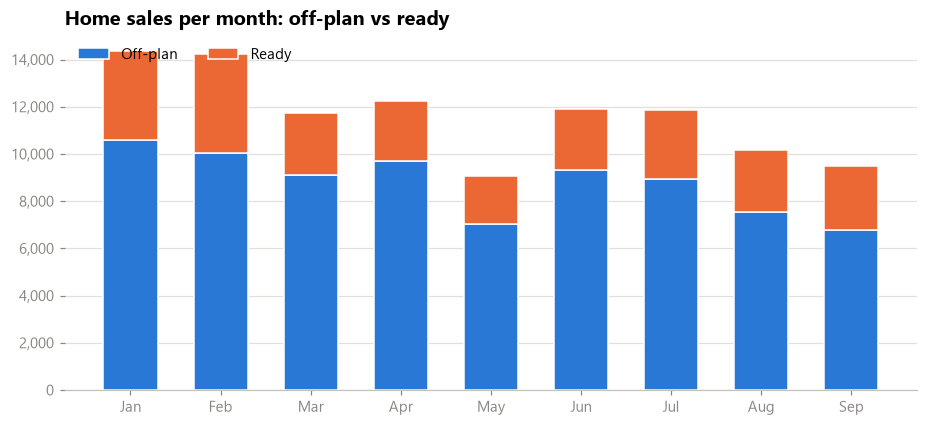

In [7]:
offplan = sql_file('03_offplan_vs_ready')
display(offplan)
fig, ax = plt.subplots()
m = offplan['month'].dt.strftime('%b')
ax.bar(m, offplan['offplan_transactions'], color=BLUE, width=0.6, label='Off-plan', edgecolor='white', linewidth=1)
ax.bar(m, offplan['ready_transactions'], bottom=offplan['offplan_transactions'], color=ORANGE, width=0.6, label='Ready', edgecolor='white', linewidth=1)
ax.set_title('Home sales per month: off-plan vs ready'); ax.legend(frameon=False, ncols=2, loc='upper left')
ax.yaxis.set_major_formatter(mt.StrMethodFormatter('{x:,.0f}'))
plt.show()

## 4. Areas: where the demand is and what it costs

,area,transactions,total_value_aed,median_price_aed,median_price_sqft,offplan_share_pct,price_change_pct,demand_rank,price_rank
0,Madinat Al Mataar,11242,"12,270,003,995.3","773,000.0","1,703.0",100.0,8.0,1,40
1,Jumeirah Village Circle,7156,"7,678,894,630.1","1,000,000.0","1,458.0",58.8,-5.5,2,54
2,Dubai Land Residence Complex,4755,"4,419,575,304.9","806,606.0","1,424.0",90.9,-5.5,3,57
3,Majan,3905,"3,462,368,380.9","720,999.0","1,424.0",83.5,-4.1,4,58
4,Business Bay,3537,"10,051,752,375.1","2,076,045.9","2,406.0",53.9,-19.8,5,19
5,Palm Deira,3278,"11,337,414,466.8","2,862,828.0","2,815.0",100.0,-10.6,6,12
6,City Of Arabia,2451,"2,104,865,702.0","612,000.0","1,701.0",99.0,3.7,7,41
7,Arjan,2407,"2,562,121,066.9","939,510.0","1,585.0",63.9,-1.8,8,51
8,Dubai Production City,2306,"2,291,345,725.8","971,950.0","1,347.0",76.4,4.4,9,62
9,Jabal Ali First,2276,"3,889,443,858.2","1,657,065.0","1,659.0",98.2,11.1,10,45


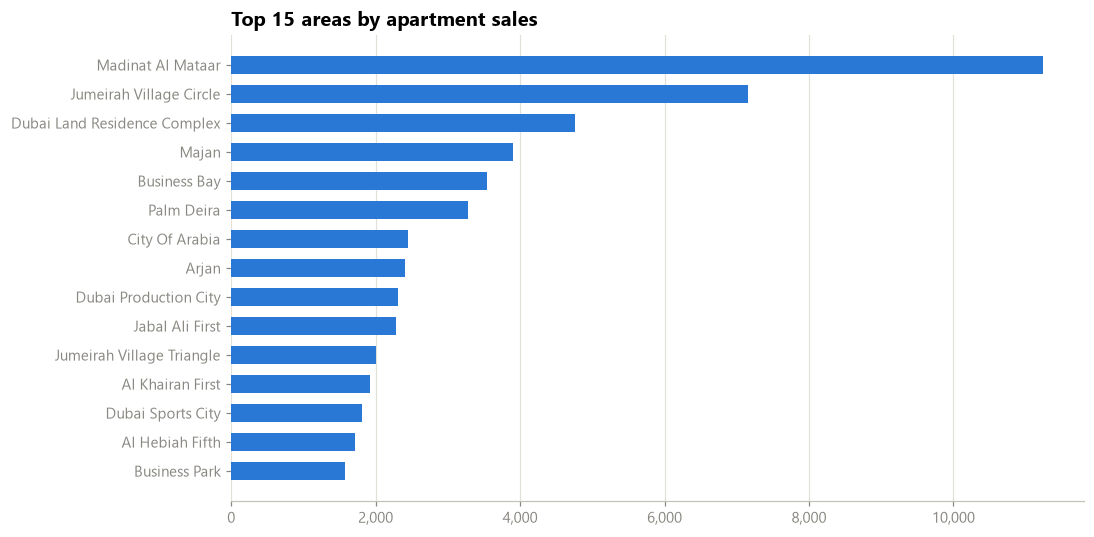

In [8]:
areas = sql_file('02_area_leaderboard')
display(areas.head(20))
top = areas.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(top['area'], top['transactions'], color=BLUE, height=0.6)
ax.set_title('Top 15 areas by apartment sales'); ax.grid(axis='x', color=GRID); ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(mt.StrMethodFormatter('{x:,.0f}'))
plt.show()

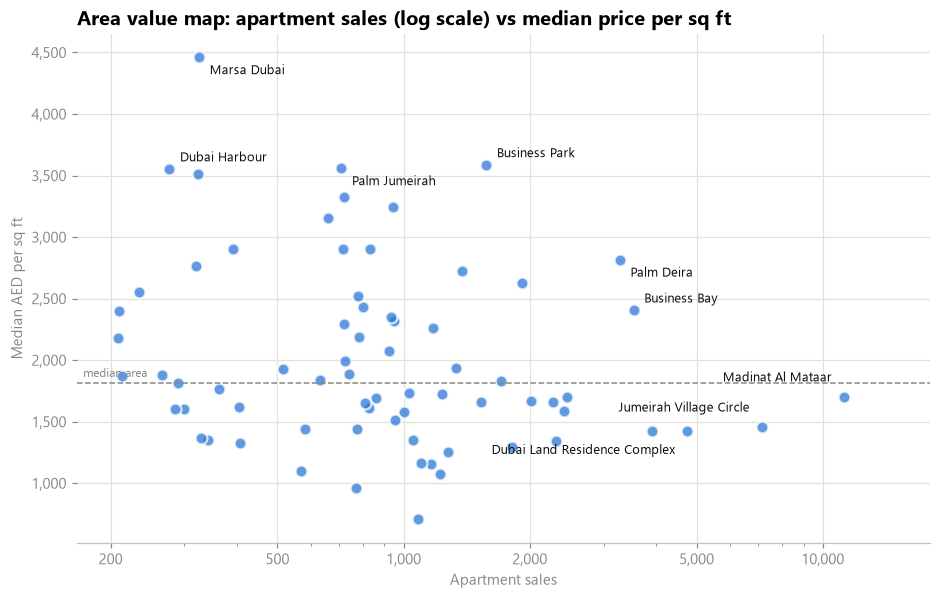

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(areas['transactions'], areas['median_price_sqft'], s=60, color=BLUE, alpha=0.75, edgecolor='white', linewidth=1.5)
ax.set_xscale('log'); ax.grid(axis='both', color=GRID)
ax.set_xticks([200, 500, 1000, 2000, 5000, 10000]); ax.set_xlim(areas['transactions'].min() * 0.8, areas['transactions'].max() * 1.6)
ax.xaxis.set_minor_formatter(mt.NullFormatter()); ax.xaxis.set_major_formatter(mt.StrMethodFormatter('{x:,.0f}'))
# The 3 busiest areas sit at the right edge: label them on the left, staggered so they don't collide.
for (_, r), dy in zip(areas.head(3).iterrows(), (10, 10, -15)):
    ax.annotate(r['area'], (r['transactions'], r['median_price_sqft']), xytext=(-8, dy),
                textcoords='offset points', fontsize=8.5, color=INK, ha='right')
others = pd.concat([areas.iloc[4:6], areas.nlargest(4, 'median_price_sqft')]).drop_duplicates('area')
for i, (_, r) in enumerate(others.sort_values('median_price_sqft').iterrows()):
    ax.annotate(r['area'], (r['transactions'], r['median_price_sqft']), xytext=(7, -11 if i % 2 else 5),
                textcoords='offset points', fontsize=8.5, color=INK)
ax.axhline(areas['median_price_sqft'].median(), color=MUTED, lw=1, ls='--')
ax.annotate('median area', (ax.get_xlim()[0], areas['median_price_sqft'].median()), xytext=(4, 4), textcoords='offset points', fontsize=8, color=MUTED)
ax.set_title('Area value map: apartment sales (log scale) vs median price per sq ft')
ax.set_xlabel('Apartment sales'); ax.set_ylabel('Median AED per sq ft')
ax.yaxis.set_major_formatter(mt.StrMethodFormatter('{x:,.0f}'))
plt.show()

Areas **below the dashed line with high volume** are the affordable, liquid markets (easy to buy and resell).
Areas **high up on the left** are premium, thinly traded markets.

In [10]:
movers = areas.dropna(subset=['price_change_pct']).sort_values('price_change_pct')
display(pd.concat([movers.tail(8), movers.head(5)])[['area', 'transactions', 'median_price_sqft', 'price_change_pct']])

,area,transactions,median_price_sqft,price_change_pct
17,Dubai Marina,1337,"1,938.0",7.4
0,Madinat Al Mataar,11242,"1,703.0",8.0
23,International City Ph 2 & 3,1101,"1,163.0",10.6
31,Horizon,934,"2,347.0",10.7
9,Jabal Ali First,2276,"1,659.0",11.1
33,Damac Hills,859,"1,690.0",16.3
57,Living Legends,342,"1,353.0",23.3
35,Down Town Jabal Ali,827,"1,612.0",26.3
4,Business Bay,3537,"2,406.0",-19.8
47,Palm Jumeirah,710,"3,558.0",-18.6


## 5. What buyers buy

,segment,rooms,price_band,transactions,median_price_aed,median_size_sqft,median_price_sqft
1,Apartment,1 B/R,All,38647,"1,246,715.0",776.0,"1,637.0"
4,Apartment,Studio,All,29338,"673,230.0",390.0,"1,737.0"
6,Apartment,2 B/R,All,21629,"2,189,888.0","1,247.0","1,762.0"
8,Apartment,3 B/R,All,5192,"3,889,804.0","1,853.0","2,089.0"
9,Villa,4 B/R,All,4719,"2,904,000.0","1,551.0","1,797.0"
11,Villa,3 B/R,All,2491,"3,125,000.0","1,873.0","1,672.0"
12,Villa,5 B/R,All,1573,"4,500,900.0","2,514.0","1,807.0"
14,Apartment,4 B/R,All,600,"10,385,500.0","3,736.0","2,872.0"
15,Villa,2 B/R,All,592,"1,547,037.0","1,096.0","1,328.0"
16,Villa,1 B/R,All,62,"975,000.0",582.0,"1,548.0"


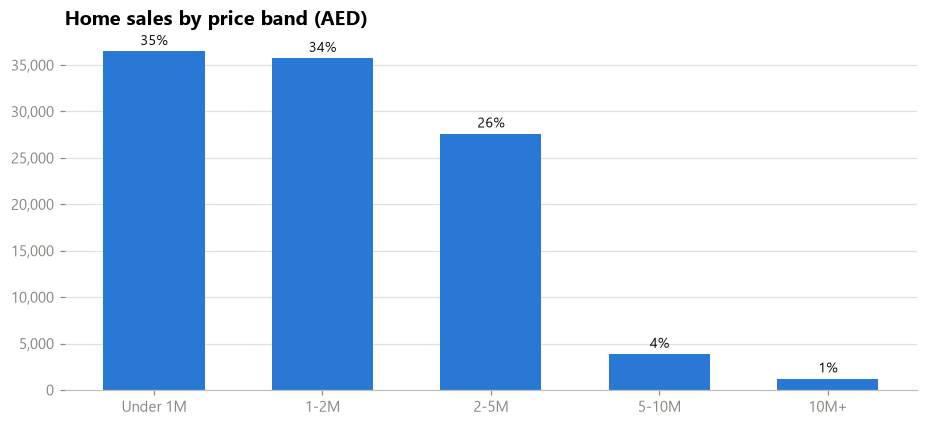

In [11]:
seg = sql_file('05_segments')
rooms = seg[(seg.price_band == 'All') & (seg.rooms != 'All') & (seg.segment.isin(['Apartment', 'Villa']))]
display(rooms.head(12))
bands = seg[seg.price_band != 'All'].set_index('price_band').reindex(['Under 1M', '1-2M', '2-5M', '5-10M', '10M+'])
fig, ax = plt.subplots()
ax.bar(bands.index, bands['transactions'], color=BLUE, width=0.6)
for i, v in enumerate(bands['transactions']):
    ax.annotate(f'{v / bands.transactions.sum():.0%}', (i, v), xytext=(0, 4), textcoords='offset points', ha='center', fontsize=9, color=INK)
ax.set_title('Home sales by price band (AED)'); ax.yaxis.set_major_formatter(mt.StrMethodFormatter('{x:,.0f}'))
plt.show()

## 6. Projects that drive the market

In [12]:
projects = sql_file('04_top_projects')
projects[['project', 'area', 'transactions', 'total_value_aed', 'median_price_sqft', 'offplan_share_pct', 'share_of_market_value_pct']].head(15)

,project,area,transactions,total_value_aed,median_price_sqft,offplan_share_pct,share_of_market_value_pct
0,LUNAYA,Saih Shuaib 1,395,"3,155,657,901.8","2,712.0",100.0,1.7
1,Hado By Beyond,Palm Deira,623,"2,457,002,460.0","3,156.0",100.0,1.3
2,Creek Bay,Al Khairan First,685,"2,233,607,030.0","2,739.0",100.0,1.2
3,THE MERIVA COLLECTION,Palm Deira,478,"2,141,566,784.0","3,448.0",100.0,1.1
4,Aman Residences Dubai,Jumeirah Second,20,"2,118,213,695.5","13,450.0",100.0,1.1
5,Passo By Beyond,Palm Jumeirah,154,"1,846,139,460.0","6,269.0",100.0,1.0
6,Maybach Six,Business Park,1032,"1,762,411,223.8","3,613.0",100.0,0.9
7,ELTIERA VIEWS,Al Thanyah Fifth,625,"1,626,159,672.0","2,498.0",100.0,0.9
8,AZIZI VENICE 14,Madinat Al Mataar,1941,"1,478,754,593.0","1,652.0",100.0,0.8
9,DAMAC ISLANDS 2 - BAHAMAS 2,Al Yelayiss 1,467,"1,465,942,855.0","1,822.0",100.0,0.8


## 7. Rental yield: where does an apartment pay back fastest?

Gross yield = median annual rent per sq ft (new leases, September 2026) ÷ median sale price per sq ft (ready apartments).
Off-plan prices are excluded because they include a premium for a home that does not exist yet.

**A data problem worth knowing:** DLD's rent records use official land-area names ("Al Barsha South Fourth"),
while sales use community names ("Jumeirah Village Circle"), so joining on area matched only 10 areas.
The building (project) name appears in both, so `sql/06_rental_yield.sql` maps every building to its sales area
and uses **only buildings that have both ready sales and new leases** — rent and price come from the same towers.

**A second one:** the rent export lists some contracts once under every building of a master community (one Creek Beach
lease appears under all 12 Creek Beach towers). Those 8,665 rows cannot be tied to a building, so `01_clean.py` drops them.
Coverage: 31 areas with 3+ buildings, 50+ ready sales and 50+ leases each.

,area,buildings,ready_sales,leases,median_price_aed,median_annual_rent_aed,median_price_sqft,median_rent_sqft,gross_yield_pct,years_of_rent_to_buy,yield_rank,service_charge_building,service_charge_aed_sqft,net_yield_pct,service_charge_share_of_rent_pct
0,Dubai Investment Park Second,3,174,68,"579,697.0","66,000.0",747.0,72.5,9.7,10.3,1,None,NaN,NaN,NaN
1,Dubai Land Residence Complex,12,353,189,"595,000.0","46,800.0",772.0,72.0,9.3,10.7,2,Sky Courts - Sky Courts - Tower A - Dubai Land,12.2,7.8,17.0
2,International City Ph 1,14,195,156,"500,000.0","41,000.0",742.0,67.2,9.1,11.0,3,None,NaN,NaN,NaN
3,Dubai Production City,9,388,214,"475,976.0","40,000.0",879.0,78.6,8.9,11.2,4,Lakeside - International Media Production Zone,13.9,7.4,17.6
4,Liwan,27,177,98,"620,000.0","49,000.0",827.0,69.5,8.4,11.9,5,None,NaN,NaN,NaN
5,International City Ph 2 & 3,14,109,73,"675,000.0","60,000.0",967.0,79.3,8.2,12.2,6,None,NaN,NaN,NaN
6,Silicon Oasis,48,564,264,"720,000.0","50,000.0",941.0,76.9,8.2,12.2,7,Binghatti Stars - Silicon Oasis,11.8,6.9,15.4
7,Dubai Sports City,47,638,446,"650,000.0","49,500.0",960.0,78.2,8.2,12.3,8,Eagle Heights - Dubai Sports City,16.7,6.4,21.3
8,Dubai Studio City,9,244,131,"610,000.0","50,000.0","1,393.0",105.1,7.5,13.3,9,None,NaN,NaN,NaN
9,Arjan,42,779,538,"860,000.0","53,571.0","1,372.0",100.9,7.3,13.6,10,None,NaN,NaN,NaN


price_tier
Cheapest third   8.2
Middle third     7.0
Priciest third   5.4
Name: median gross yield %, dtype: float64

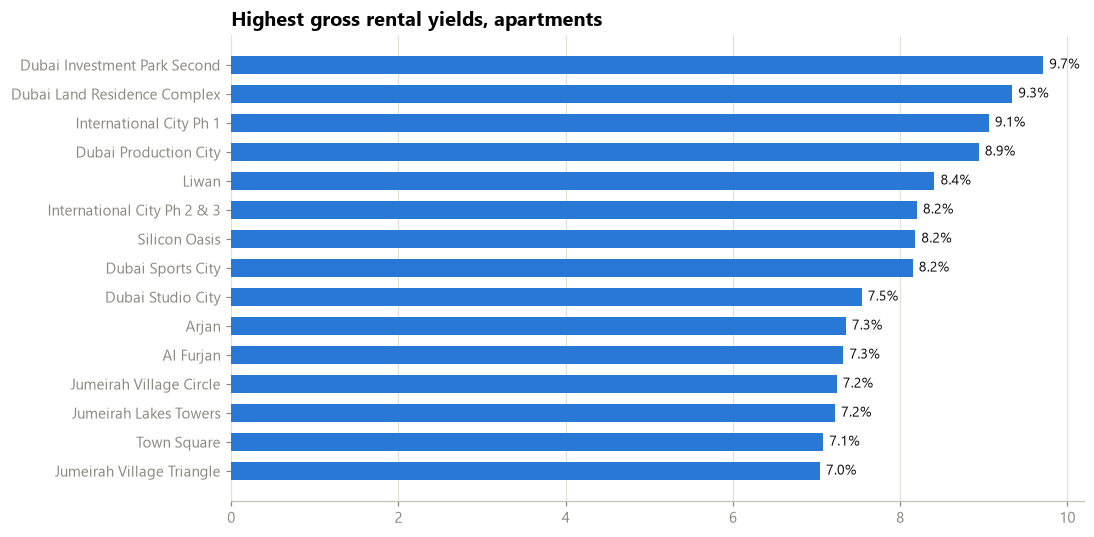

In [13]:
ry = q('SELECT * FROM mart_rental_yield ORDER BY gross_yield_pct DESC')
display(ry.head(15))
ry['price_tier'] = pd.qcut(ry['median_price_sqft'], 3, labels=['Cheapest third', 'Middle third', 'Priciest third'])
display(ry.groupby('price_tier', observed=True)['gross_yield_pct'].median().round(1).rename('median gross yield %'))
top = ry.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(top['area'], top['gross_yield_pct'], color=BLUE, height=0.6)
for i, v in enumerate(top['gross_yield_pct']):
    ax.annotate(f'{v:.1f}%', (v, i), xytext=(4, 0), textcoords='offset points', va='center', fontsize=9, color=INK)
ax.set_title('Highest gross rental yields, apartments'); ax.grid(axis='x', color=GRID); ax.grid(axis='y', visible=False)
plt.show()

### Net of service charges: what an investor actually keeps

Owners pay a yearly service charge per sq ft, approved by RERA and published in DLD's **Service Charge Index**.
DLD only shows it one project at a time behind a captcha, so the 2026 rate of each area's most-rented building
(with a 2026 rate) was looked up by hand into `data/reference/service_charges_2026.csv`.
Net yield = (rent per sq ft − service charge per sq ft) ÷ price per sq ft. Vacancy, maintenance inside the unit and fees are not deducted.

,area,price_tier,gross_yield_pct,service_charge_aed_sqft,service_charge_share_of_rent_pct,net_yield_pct,service_charge_building
0,Dubai Land Residence Complex,Cheapest third,9.3,12.2,17.0,7.8,Sky Courts - Sky Courts - Tower A - Dubai Land
1,Dubai Production City,Cheapest third,8.9,13.9,17.6,7.4,Lakeside - International Media Production Zone
2,Silicon Oasis,Cheapest third,8.2,11.8,15.4,6.9,Binghatti Stars - Silicon Oasis
3,Dubai Sports City,Cheapest third,8.2,16.7,21.3,6.4,Eagle Heights - Dubai Sports City
4,Jumeirah Village Circle,Middle third,7.2,17.5,18.6,5.9,Binghatti Apex - Jumeirah Village Circle
5,Meydan One,Priciest third,6.4,14.9,11.9,5.6,Azizi Riviera 46 - Meydan
6,Sobha Heartland,Priciest third,6.1,17.4,14.1,5.3,"The Crest, Sobha Hartland - SOBHA HARTLAND"
7,Dubai Hills,Priciest third,5.7,15.9,11.9,5.1,Park Ridge - Dubai Hills Estate
8,Dubai Creek Harbour,Priciest third,5.2,16.2,13.1,4.5,The Grand - Dubai Creek Harbour
9,Dubai Harbour,Priciest third,4.8,19.3,12.2,4.2,Marina Vista - Marina Vista Residential - Unsp...


,gross_yield_pct,net_yield_pct,service_charge_share_of_rent_pct
price_tier,,,
Cheapest third,8.6,7.1,17.3
Middle third,7.2,5.9,18.6
Priciest third,5.5,4.8,12.6


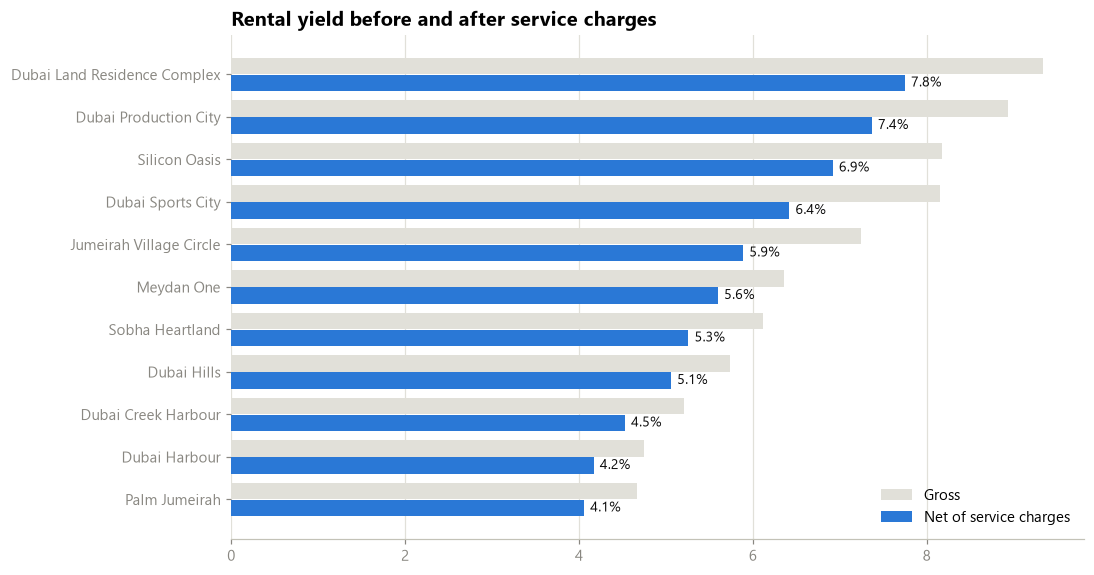

In [14]:
net = ry.dropna(subset=['net_yield_pct']).sort_values('net_yield_pct', ascending=False)
display(net[['area', 'price_tier', 'gross_yield_pct', 'service_charge_aed_sqft', 'service_charge_share_of_rent_pct',
             'net_yield_pct', 'service_charge_building']].reset_index(drop=True))
display(net.groupby('price_tier', observed=True)[['gross_yield_pct', 'net_yield_pct', 'service_charge_share_of_rent_pct']]
        .median().round(1))
plot = net.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 0.45 * len(plot) + 1))
y = range(len(plot))
ax.barh([i + 0.2 for i in y], plot['gross_yield_pct'], height=0.38, color=GRID, label='Gross')
ax.barh([i - 0.2 for i in y], plot['net_yield_pct'], height=0.38, color=BLUE, label='Net of service charges')
for i, v in enumerate(plot['net_yield_pct']):
    ax.annotate(f'{v:.1f}%', (v, i - 0.2), xytext=(4, 0), textcoords='offset points', va='center', fontsize=9, color=INK)
ax.set_yticks(list(y), plot['area']); ax.legend(frameon=False, loc='lower right')
ax.set_title('Rental yield before and after service charges'); ax.grid(axis='x', color=GRID); ax.grid(axis='y', visible=False)
plt.show()

## 8. Data limitations

- DLD's open export covers the **current year only**, so year-on-year growth cannot be measured from it.
- Price per sq ft uses the registered transaction size; for villas DLD sometimes registers plot size, which lowers their price per sq ft.
- "Off-plan" follows DLD's registration type; resales of off-plan units before handover are counted as off-plan.
- Some large villa launches (e.g. Mareva at The Oasis, Eden Hills) are registered as **land plots** ("Delayed Sell", Ready), so off-plan villa activity is understated and these projects appear under Land.
- Seasonality (Ramadan in March, Eid in May, summer) cannot be separated from trend without earlier years.
- Rents are Ejari registrations from **one month** (September 2026). Net yields deduct service charges only (not vacancy, maintenance or fees), and use one building's rate per area.

## 9. Findings and recommendations

**Findings (Jan–Sep 2026, 121,741 sales, AED 376 bn; 25,988 September leases)**
1. **Activity cooled:** 17,192 sales in January → 11,038 in September (−36%), partly seasonal.
2. **Off-plan is 75% of home sales**, peaking at 79.5% in April and easing to 71.5% in September. Off-plan apartments cost 26% more per sq ft than ready ones, but only ~8% more per deal — buyers get smaller homes.
3. **Like-for-like prices eased 2.3%** (peak +4.1% in April). The simple average fell 12.4% — 10.1 points of that is a mix effect (more sales in cheaper areas). The simple average overstates the fall ~5×.
4. **Demand is concentrated in affordable areas:** Madinat Al Mataar, JVC and Dubai Land Residence Complex take 24% of apartment sales; 10 of the 15 busiest areas are below the city median of AED 1,714 per sq ft.
5. **Mid-market buyers:** 68% of homes under AED 2M; 71% of apartments are studios or 1-bedrooms.
6. **Cheaper areas pay back faster:** across 31 areas (same buildings on both sides), the cheapest third earns a median 8.2% gross yield vs 5.4% for the priciest third. Top: Dubai Investment Park Second 9.7%, Dubai Land Residence Complex 9.3%, International City Ph 1 9.1%; lowest: Palm Jumeirah 4.7%.
7. **After service charges, cheaper areas still win — by less:** for the 11 areas with a 2026 DLD service-charge rate, the cheapest third nets 7.1% vs 4.5% for the priciest (gap 3.3 → 2.6 points). Service charges take 17% of rent in cheaper areas vs 13% in prime ones. Top net: Dubai Land Residence Complex 7.8%; lowest: Palm Jumeirah 4.1%.

**Recommendations**
- *Buyers:* ready apartments are ~21% cheaper per sq ft and prices are 6.1% below the April peak — compare ready stock in JVC, Arjan and Dubai Sports City, and negotiate.
- *Income investors:* compare yields net of service charges. Affordable communities (Dubai Land Residence Complex, Dubai Production City, Silicon Oasis) keep 7–8% after service charges and pay back in ~11–12 years of rent vs ~21 on Palm Jumeirah and Dubai Harbour.
- *Growth investors:* prime areas net about 4%, so they only make sense with price growth — and Palm Jumeirah's median price per sq ft fell this year; check the project mix first.
- *Brokers/developers:* focus on studios/1-bedrooms under AED 2M (7 in 10 apartment deals) and build resale listings as the off-plan share slips.

**Next steps:** service charges for the remaining areas, 2024–2025 for year-on-year comparison, more months of leases, and a 6-month price forecast.
